# **CSMODEL MCO1** #
By Project Group 4
- GO, CLYDE KENDALL
- GO, MIGUEL JOAQUIN
- TAN, LANCE JERWIN
- TIU, KYLE THOMAS
- UY, TARA YSABEL

## **1. Abstract** ##

[ PLACE ABSTRACT HERE ]

## **2.Dataset Description** ##

The dataset chosen by the group was taken from [490K Spotify Song Audio Embeddings & Metadata](https://www.kaggle.com/datasets/serkantysz/490k-spotify-song-audio-embeddings-and-metadata?select=songs.csv) by Serkan Tüysüz, which can be found in Kaggle, an online platform that contains various datasets made by different researchers.

In [ ]:
# import necessary libaries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [74]:
# read the csv file
spotify_df = pd.read_csv('songs.csv')
print("CSV read successfully")

CSV read successfully


This dataset contains 491632 songs which consists of metadata, features, lyrics, artists data and audio embeds.

In [75]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 491632 entries, 0 to 491631
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      491632 non-null  str    
 1   name                    491632 non-null  str    
 2   album_name              491619 non-null  str    
 3   artists                 491632 non-null  str    
 4   danceability            491632 non-null  float64
 5   energy                  491632 non-null  float64
 6   key                     491632 non-null  int64  
 7   loudness                491632 non-null  float64
 8   mode                    491632 non-null  int64  
 9   speechiness             491632 non-null  float64
 10  acousticness            491632 non-null  float64
 11  instrumentalness        491632 non-null  float64
 12  liveness                491632 non-null  float64
 13  valence                 491632 non-null  float64
 14  tempo                   491632 

#### **Data Collection** ####
This dataset is a refinement of a preexisting dataset on Kaggle called [🎹 960K Spotify Songs With Lyrics data 🎵](https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics) made by user "BwandoWando". While the original dataset gathered its data from several other datasets with large amounts of entries, Tüysüz noticed that there seemed to be significant inconsistencies in formatting and missing and outdated information included in the dataset. As such, dataset by Tüysüz used the official Spotify API along with third-party tools such as VGGish and PANNs to ensure the data integrity and add new useful metadata to the dataset. It should be noted that only english songs were included. 

All of the data were taken from multiple other datasets listed in Kaggle, with which those Spotify tracks were taken and retrieved from the Spotify Web API. 

The group chose this dataset as Spotify and music are concepts familiar within the group and is relevant in current society due to its high usage. Having preliminary knowledge of the topic is a great help in studying the dataset. The dataset also contains a sufficient amount of observations and variables.

Due to the data collection, the dataset may be biased due to music data only being taken from Spotify, excluding on who can upload and the types of music. Additionally, the millions of possible songs may not be represented well by the 490K songs only in the dataset. Selection bias may also have been seen due to other historic songs not found on Spotify.

The structure of this dataset consists of the individual songs listed in each row and the attributes of the songs listed as the columns of the dataset. The description of each attribute for each song (seen in ‘info()’) contains the following:

#### **Track Data** ####
| Feature Name | Description |
| :--- | ---: |
| id | Unique Spotify ID of the track. |
| name | Track name |
| album_name | Album name |
| artists | Track's artist/s |
| lyrics | Full lyrics of the song (fetched from LRCLIB) |
| year | Release year of the track |
| genre | Main genre of the track |
| popularity | Spotify popularity score |
| niche_genres | Specific sub-genres associated with the track/artist |

#### **Track Features** ####
| Feature Name | Description |
| :--- | ---: |
| danceability | Measure of how suitable a track is for dancing (0.0 to 1.0) |
| energy | Perceptual measure of intensity and activity (0.0 to 1.0) |
| key | The key the track is in (Integer mapping to standard pitch class notation) (0 to 11) |
| loudness | Overall loudness of a track in decibels (dB) |
| mode | Track modality (1 = Major, 0 = Minor) |
| speechiness | Presence of spoken words in a track (0.0 to 1.0) |
| acousticness | Confidence measure of whether the track is acoustic (0.0 to 1.0) |
| instrumentalness | Predicts whether a track contains no vocals (0.0 to 1.0) |
| liveness | Measures the audience in the song (0.0 to 1.0) |
| valence | Musical positiveness conveyed by a track (0.0 to 1.0) |
| tempo | Estimated tempo of the track in beats per minute (BPM) |
| duration_ms | Duration of the track in milliseconds |

#### **Artist metrics and data** ####
| Feature Name | Description |
| :--- | ---: |
| total_artist_followers | Sum of followers for all artists on the track |
| avg_artist_popularity | Average popularity score of all artists on the track |
| artist_ids | List of Spotify IDs for the artists |


## **3. Data Cleaning and Preprocessing** ##

To ensure data integrity, multiple cleaning and preprocessing steps were executed to fix the dataset.

#### **Removal of irrelevant columns** ####
The group identifies that the id and artist_id columns do not give any relevant information about track specifics. Additionally, the lyrics data would require further text analysis, which would be out of the scope of this study. Furthermore, the track features key, acousticness, and liveness, which are identified as not relevant to the data analysis. Lastly, the niche_genre is identified to negatively impact the analysis due to these genres being too extreme or obscure, possibly leading to the analysis being too specific and irrelevant.

In [76]:
# drop variables that are not relevant to the analysis
var_to_drop = ["id", "artist_ids", "lyrics", "key", "acousticness", "liveness", "niche_genres"]
spotify_df = spotify_df.drop(columns=var_to_drop)

Recheck Structure of Dataset

In [77]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 491632 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    491632 non-null  str    
 1   album_name              491619 non-null  str    
 2   artists                 491632 non-null  str    
 3   danceability            491632 non-null  float64
 4   energy                  491632 non-null  float64
 5   loudness                491632 non-null  float64
 6   mode                    491632 non-null  int64  
 7   speechiness             491632 non-null  float64
 8   instrumentalness        491632 non-null  float64
 9   valence                 491632 non-null  float64
 10  tempo                   491632 non-null  float64
 11  duration_ms             491632 non-null  int64  
 12  year                    491632 non-null  int64  
 13  genre                   491632 non-null  str    
 14  popularity              491632 

#### **Removal of null and NaN** ####
From the sturcture, album_name contains less non-null values, indicating NaN values. For further checking:


In [78]:
spotify_df.isnull().any()

name                      False
album_name                 True
artists                   False
danceability              False
energy                    False
loudness                  False
mode                      False
speechiness               False
instrumentalness          False
valence                   False
tempo                     False
duration_ms               False
year                      False
genre                     False
popularity                False
total_artist_followers    False
avg_artist_popularity     False
dtype: bool

To check the number of observations that are NaN:

In [79]:
spotify_df[spotify_df['album_name'].isnull()]

,name,album_name,artists,danceability,energy,loudness,mode,speechiness,instrumentalness,valence,tempo,duration_ms,year,genre,popularity,total_artist_followers,avg_artist_popularity
65959,But They Respect My Tactics,NaN,"[""KEN Mode""]",0.224,0.948,-4.673,1,0.0544,0.886000,0.179,158.075,187040,2022,Rock,9,30335,21.000000
100298,Delusion,NaN,"[""Gupi""]",0.375,0.614,-5.691,1,0.0972,0.142000,0.818,169.985,188338,2020,Electronic,12,32909,40.000000
131006,False Awakening,NaN,"[""Gupi""]",0.610,0.971,-4.552,0,0.0958,0.051900,0.861,150.000,191693,2020,Electronic,28,32909,40.000000
249350,Lost Grip,NaN,"[""KEN Mode""]",0.252,0.674,-7.179,0,0.0352,0.745000,0.153,130.625,602000,2022,Rock,8,30335,21.000000
269670,Modern Times Rock 'n' Roll,NaN,['Queen'],0.480,0.838,-12.855,0,0.0505,0.000067,0.561,115.603,108373,1973,Rock,0,55564836,85.000000
269686,Modest,NaN,"[""Gupi""]",0.729,0.668,-5.135,1,0.0503,0.000013,0.947,117.033,182126,2020,Electronic,27,32909,40.000000
309045,Paradise,NaN,"[""Gupi""]",0.640,0.972,-5.048,0,0.1500,0.607000,0.841,170.010,197836,2020,Electronic,13,32909,40.000000
309209,Paradise Regained,NaN,"[""Inked In Blood""]",0.423,0.832,-6.898,1,0.0274,0.020400,0.489,175.003,568307,2007,Rock,1,4474,7.000000
338736,Roots To Branches - Live,NaN,"[""Jethro Tull""]",0.371,0.648,-7.490,0,0.0740,0.000155,0.393,149.334,334840,2002,Rock,0,1981589,60.000000
341281,Running Back,NaN,"[""How To Dress Well""]",0.767,0.331,-9.841,0,0.0474,0.002710,0.390,95.739,197218,2012,Pop,8,87460,27.000000


In [80]:
# drop rows with NaN values
spotify_df.dropna(inplace=True)

To check if rows have been removed:

In [81]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 491619 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    491619 non-null  str    
 1   album_name              491619 non-null  str    
 2   artists                 491619 non-null  str    
 3   danceability            491619 non-null  float64
 4   energy                  491619 non-null  float64
 5   loudness                491619 non-null  float64
 6   mode                    491619 non-null  int64  
 7   speechiness             491619 non-null  float64
 8   instrumentalness        491619 non-null  float64
 9   valence                 491619 non-null  float64
 10  tempo                   491619 non-null  float64
 11  duration_ms             491619 non-null  int64  
 12  year                    491619 non-null  int64  
 13  genre                   491619 non-null  str    
 14  popularity              491619 non-n

#### **Remove zeroes in the popularity** ####

The group has also decided to remove songs that have a popularity value of 0 as these songs may not be representative of the active consumer engagement and may skew the results in our analysis.

In [82]:
# check number of 0s in popularity column
spotify_df['popularity'].value_counts()

popularity
0     128570
1      11119
2       8932
22      8333
21      8305
       ...  
98         3
91         3
96         2
93         1
95         1
Name: count, Length: 97, dtype: int64

It is illogical for 128570 songs to have 0 popularity. This may possibly be an error or imputation. Dropping the values will be the most reasonable action to take in this situation.

In [83]:
# drop observations with 0 popularity
spotify_df = spotify_df[spotify_df['popularity'] != 0]
spotify_df['popularity'].value_counts()

popularity
1     11119
2      8932
22     8333
21     8305
18     8198
      ...  
98        3
91        3
96        2
93        1
95        1
Name: count, Length: 96, dtype: int64

In [84]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 363049 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    363049 non-null  str    
 1   album_name              363049 non-null  str    
 2   artists                 363049 non-null  str    
 3   danceability            363049 non-null  float64
 4   energy                  363049 non-null  float64
 5   loudness                363049 non-null  float64
 6   mode                    363049 non-null  int64  
 7   speechiness             363049 non-null  float64
 8   instrumentalness        363049 non-null  float64
 9   valence                 363049 non-null  float64
 10  tempo                   363049 non-null  float64
 11  duration_ms             363049 non-null  int64  
 12  year                    363049 non-null  int64  
 13  genre                   363049 non-null  str    
 14  popularity              363049 non-n

#### **Removal of song duplicates** ####
Songs may be duplicated. To check this:

In [85]:
duplicates = spotify_df[spotify_df.duplicated(keep=False)]

In [86]:
# check how many duplicates there are
print(duplicates)

                                         name  \
43261                              Be the One   
43263                              Be the One   
75335                       Charlie Be Quiet!   
75336                       Charlie Be Quiet!   
79775                               Cleopatra   
79778                               Cleopatra   
93890                           Dance Macabre   
93893                           Dance Macabre   
111780                             Dope Fiend   
111782                             Dope Fiend   
149810                               Get Busy   
149812                               Get Busy   
171143                 Hearts Burst into Fire   
171144                 Hearts Burst into Fire   
190650       I Found a Reason - 2015 Remaster   
190651       I Found a Reason - 2015 Remaster   
191276  I Got the Keys (feat. JAY-Z & Future)   
191279  I Got the Keys (feat. JAY-Z & Future)   
208280                               In Bloom   
208281              

In [87]:
spotify_df.drop_duplicates(inplace=True)

To check if duplicates have been dropped:

In [88]:
duplicates2 = spotify_df[spotify_df.duplicated(keep=False)]
print(duplicates2)

Empty DataFrame
Columns: [name, album_name, artists, danceability, energy, loudness, mode, speechiness, instrumentalness, valence, tempo, duration_ms, year, genre, popularity, total_artist_followers, avg_artist_popularity]
Index: []


#### **Check if metadata values are in range** ####
This is done to make sure values of variables are in range (according to dataset description).

In [89]:
print("Popularity:")
print(spotify_df['popularity'].min())
print(spotify_df['popularity'].max())
print()
print("Danceability")
print(spotify_df['danceability'].min())
print(spotify_df['danceability'].max())
print()
print("Energy")
print(spotify_df['energy'].min())
print(spotify_df['energy'].max())
print()
print("loudness")
print(spotify_df['loudness'].min())
print(spotify_df['loudness'].max())
print()
print("mode")
print(spotify_df['mode'].min())
print(spotify_df['mode'].max())
print()
print("speechiness")
print(spotify_df['speechiness'].min())
print(spotify_df['speechiness'].max())
print()
print("instrumentalness")
print(spotify_df['instrumentalness'].min())
print(spotify_df['instrumentalness'].max())
print()
print("valence")
print(spotify_df['valence'].min())
print(spotify_df['valence'].max())
print()
print("tempo")
print(spotify_df['tempo'].min())
print(spotify_df['tempo'].max())
print()
print("duration_ms")
print(spotify_df['duration_ms'].min())
print(spotify_df['duration_ms'].max())

Popularity:
1
98

Danceability
0.0455
0.988

Energy
2.03e-05
1.0

loudness
-39.67
0.0

mode
0
1

speechiness
0.022
0.965

instrumentalness
0.0
0.998

valence
0.0
0.996

tempo
30.946
244.08

duration_ms
16640
1284627


All variables are in there ranges aside from variables that do not have ranges from the dataset descriptions, specifically tempo, mode, and duration_ms.

To check if values under "mode" variable are valid, they must be either 1 or 0 only.

In [90]:
spotify_df['mode'].value_counts()

mode
1    241614
0    121411
Name: count, dtype: int64

For tempo and duration_ms, since they have various values in the dataset, different checking is needed, specifically value_counts and boxplot for outlier detection.

In [91]:
spotify_df['duration_ms'].value_counts()

duration_ms
240000    191
192000    175
180000    154
210000    142
200000    122
         ... 
126302      1
265301      1
477294      1
356752      1
191922      1
Name: count, Length: 98350, dtype: int64

<Axes: title={'center': 'Boxplot for duration_ms, outlier detection'}>

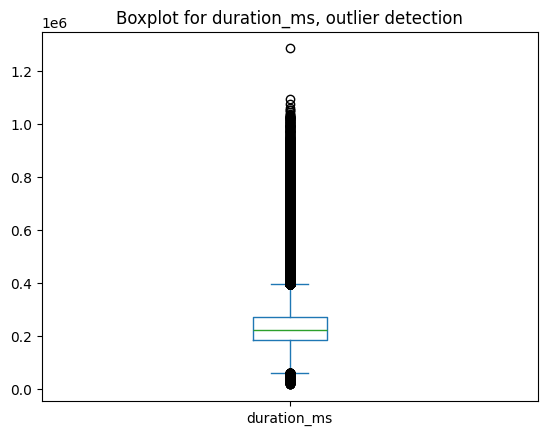

In [92]:
spotify_df['duration_ms'].plot.box(title="Boxplot for duration_ms, outlier detection")

For duration_ms, removing all outliers outside of the box will destroy the data, especially since outliers are very close to one another, thus keeping them would be the viable option.

In [93]:
spotify_df['tempo'].value_counts()

tempo
120.012    100
119.999     96
120.006     95
120.001     89
120.004     88
          ... 
131.544      1
75.395       1
119.303      1
186.012      1
178.292      1
Name: count, Length: 103453, dtype: int64

<Axes: title={'center': 'Boxplot for tempo, outlier detection'}>

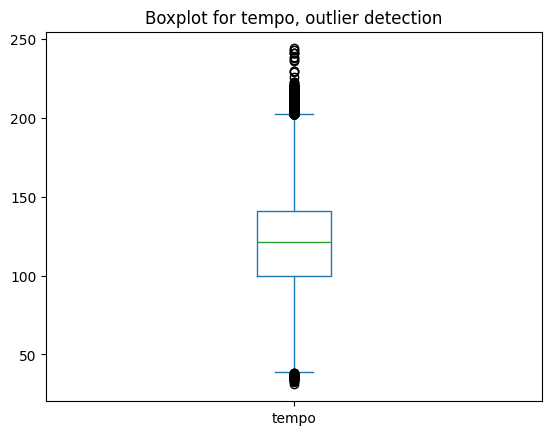

In [94]:
spotify_df['tempo'].plot.box(title="Boxplot for tempo, outlier detection")

Similar to duration_ms, removing the outliers will destroy the data. It's possible that songs will have a high tempo and should be considered in this study.

#### **Find unique genres to check if all representation are valid** ####

In [95]:
spotify_df['genre'].unique()

<StringArray>
[   'Hip-Hop',       'Rock',  'Classical',        'Pop',      'Blues',
    'Country',       'Folk', 'Electronic',       'Jazz',        'R&B']
Length: 10, dtype: str

In [96]:
spotify_df['genre'].value_counts()

genre
Rock          130710
Pop            47954
Electronic     44625
Country        31353
Folk           30706
Hip-Hop        29292
R&B            19439
Jazz           11406
Blues          10385
Classical       7155
Name: count, dtype: int64

#### **Conversion of miliseconds in duration to seconds for easier digestion** ####

In [97]:
spotify_df['duration_ms'] = spotify_df['duration_ms'] * 0.001
spotify_df['duration_ms']

0         114.000
2         178.533
7         237.973
9         226.200
10        157.667
           ...   
491627    477.294
491628    356.752
491629    191.922
491630    159.267
491631    179.573
Name: duration_ms, Length: 363025, dtype: float64

#### FINAL STUCTURE + EXPORT TO NEW CSV FOR SAFETY

128594 rows filtered out. 363205 observations left.

In [98]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 363025 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    363025 non-null  str    
 1   album_name              363025 non-null  str    
 2   artists                 363025 non-null  str    
 3   danceability            363025 non-null  float64
 4   energy                  363025 non-null  float64
 5   loudness                363025 non-null  float64
 6   mode                    363025 non-null  int64  
 7   speechiness             363025 non-null  float64
 8   instrumentalness        363025 non-null  float64
 9   valence                 363025 non-null  float64
 10  tempo                   363025 non-null  float64
 11  duration_ms             363025 non-null  float64
 12  year                    363025 non-null  int64  
 13  genre                   363025 non-null  str    
 14  popularity              363025 non-n

EXPORT TO NEW CSV FILE FOR SAFETY (songs2.csv)

In [99]:
spotify_df.to_csv('songs2.csv', index=False)

## **4. Research Question and Exploratory Data Analysis** ##

For the group's EDA, we determined the following to be features relevant enough to be analyzed:

In [ ]:
numeric_features = [
    'danceability', 
    'energy', 
    'loudness', 
    'speechiness',
    'instrumentalness', 
    'valence', 
    'tempo', 
    'duration_ms',
    'popularity', 
    'total_artist_followers', 
    'avg_artist_popularity'
]

Additionally, due to the large size of dataset's population, the group decided to use a sample of 1% of the population for the sake of visual clarity in certain plots. 

In [ ]:
sample = len(spotify_df) // 100
sample
spotify_sample = spotify_df.sample(sample, random_state=8)

#### **1. What is the distribution of the genres in the dataset?** ####

In [ ]:
genre_count = spotify_df['genre'].value_counts()
genre_summary = pd.DataFrame(genre_count).reset_index()
genre_summary.columns = ['Genre', 'Count']
genre_summary['Percentage'] = (genre_summary['Count'] / genre_summary['Count'].sum()) * 100
genre_summary

The statistics above show how prevalent the "Rock" genre is considering that it has the most amount of songs by a large margin with 130,718 entries, consisting of about 36.01% of the entire dataset's population. 

In [ ]:
genre_count.plot.bar(figsize=(14,6))
plt.title('Distribution of Genres in Dataset')
plt.xlabel('Genre')
plt.ylabel('Number of Songs')
plt.xticks(rotation=45, ha='right')
plt.show()

The bar graph reflects the "Rock" genre's dominance of the dataset population. It also displays how close some genres are in terms of count, such as with the genres "Country", "Folk", and "Hip Hop". Possible inquiries arise on whether quantity is an indicator of a genre's popularity.  

#### **2. Are there correlations between the variables?** ####

In [ ]:
correlation = spotify_df[numeric_features].corr()
plt.figure(figsize=(12, 10))
sb.heatmap(correlation, cmap='coolwarm', annot=True)
plt.title('Correlation Matrix of Spotify Track Features', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

From the heat map, the group deduced that a majority of the variables do not have a particularly strong correlation to one another. The variables that do have a high r value do make sense. 